# Single Stock Risk Report

A **parameterized** risk report for one stock, built from the cleaned OHLC table `ohlc_hw_cleaned`.
Change the parameters in the next cell and run all cells.

**Conventions used throughout:** report returns and drawdown use `adj_close`; volatility, Sharpe and daily-return statistics use daily *log* returns; calculations keep fractions (0.05 = 5%) and percentages are formatted only for display.

## 2.1 Parameters
The cell below is tagged `parameters`, so papermill will inject overriding values right after it.

In [5]:
# Parameters
ticker = "AAPL"  # Stock ticker to analyze
start_date = "2024-01-01"  # Analysis start date
end_date = "2024-12-31"  # Analysis end date
db_path = "data/data.db"

In [6]:
import sqlite3
from contextlib import closing
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter
from IPython.display import display

# ---- Report constants -------------------------------------------------------
TABLE_NAME = "ohlc_hw_cleaned"
TRADING_DAYS = 252        # trading days per year (annualisation factor)
VOL_WINDOW = 20           # rolling volatility window (days)
MA_WINDOW = 50            # moving-average window (days)
RISK_FREE_RATE = 0.02     # annual risk-free rate used in the Sharpe ratio
MIN_PRICES = VOL_WINDOW + 1   # 20 returns need at least 21 prices

# ---- Consistent colour scheme -----------------------------------------------
COLORS = {
    "up": "#2E9E6B",       # green  : positive returns / low volatility
    "down": "#D64550",     # red    : negative returns / high volatility / drawdown
    "neutral": "#9AA3AE",  # gray   : unavailable (warm-up) estimates
    "ma": "#1F3A5F",       # navy   : moving average
    "vol": "#6C5CE7",      # violet : rolling volatility line
    "text": "#2B2F36",
    "grid": "#D5DAE1",
    "bg": "#FBFCFE",
}

plt.rcParams.update({
    "figure.facecolor": COLORS["bg"],
    "axes.facecolor": "white",
    "axes.edgecolor": COLORS["grid"],
    "axes.labelcolor": COLORS["text"],
    "axes.titleweight": "bold",
    "xtick.color": COLORS["text"],
    "ytick.color": COLORS["text"],
    "grid.color": COLORS["grid"],
    "grid.linestyle": "-",
    "grid.linewidth": 0.8,
    "font.size": 11,
    "legend.frameon": True,
    "legend.framealpha": 0.92,
    "legend.edgecolor": COLORS["grid"],
})

## 2.2 Data Loading
`load_price_data` reads the cleaned table for one ticker, validates the columns, and applies the date range.
Dates are filtered in pandas (rather than in SQL string comparisons) so the result does not depend on how `ts` happens to be stored.

In [7]:
REQUIRED_COLUMNS = ["ts", "open", "high", "low", "close", "adj_close", "volume", "ticker"]
PRICE_COLUMNS = ["open", "high", "low", "close", "adj_close"]


class InsufficientHistoryError(ValueError):
    """Raised when the selected ticker/date range has too few prices for the report."""


def load_price_data(db_path, ticker: str, start_date: str, end_date: str,
                    table: str = TABLE_NAME) -> pd.DataFrame:
    """Load cleaned OHLC data for one ticker and an inclusive date range.

    Parameters
    ----------
    db_path : str or Path
        Path to the SQLite database.
    ticker : str
        Ticker symbol (case-insensitive).
    start_date, end_date : str
        Inclusive range, anything ``pd.Timestamp`` can parse (e.g. "2024-01-01").
    table : str
        Table name (default ``ohlc_hw_cleaned``).

    Returns
    -------
    pd.DataFrame
        Indexed by ``ts`` (DatetimeIndex, sorted, unique) with columns
        open, high, low, close, adj_close, volume, ticker.
        ``df.attrs`` records the full available date range for the ticker
        (``available_first`` / ``available_last``) for use in error messages.

    Raises
    ------
    FileNotFoundError, ValueError
        If the database/table/columns are missing, the dates are invalid, or the
        ticker does not exist in the table.
    """
    ticker_norm = str(ticker).strip().upper()

    try:
        start, end = pd.Timestamp(start_date).normalize(), pd.Timestamp(end_date).normalize()
    except (ValueError, TypeError) as exc:
        raise ValueError(f"Could not parse dates start_date={start_date!r}, end_date={end_date!r}") from exc
    if pd.isna(start) or pd.isna(end):
        raise ValueError("start_date and end_date must be valid dates.")
    if start > end:
        raise ValueError(f"start_date ({start:%Y-%m-%d}) is after end_date ({end:%Y-%m-%d}).")

    path = Path(db_path)
    if not path.is_file():
        raise FileNotFoundError(
            f"Database not found at '{path}' (working directory: {Path.cwd()}). "
            "Set the db_path parameter to your local copy of data/data.db."
        )

    with closing(sqlite3.connect(str(path))) as conn:
        exists = conn.execute(
            "SELECT 1 FROM sqlite_master WHERE type IN ('table', 'view') AND name = ?", (table,)
        ).fetchone()
        if not exists:
            raise ValueError(f"Table '{table}' not found in {path}.")
        try:
            raw = pd.read_sql_query(
                f'SELECT {", ".join(REQUIRED_COLUMNS)} FROM "{table}" WHERE UPPER(ticker) = ? ORDER BY ts',
                conn, params=(ticker_norm,),
            )
        except (sqlite3.DatabaseError, pd.errors.DatabaseError) as exc:
            raise ValueError(f"Table '{table}' is missing one of the required columns {REQUIRED_COLUMNS}.") from exc

        if raw.empty:
            known = [r[0] for r in conn.execute(f'SELECT DISTINCT ticker FROM "{table}" ORDER BY ticker LIMIT 25')]
            raise ValueError(f"Ticker '{ticker_norm}' not found in '{table}'. Examples of available tickers: {known}")

    # --- clean / validate ----------------------------------------------------
    df = raw.copy()
    df["ts"] = pd.to_datetime(df["ts"], errors="coerce").dt.normalize()
    bad_ts = int(df["ts"].isna().sum())
    if bad_ts:
        print(f"Dropped {bad_ts} row(s) with an unparseable ts.")
        df = df.dropna(subset=["ts"])

    for col in PRICE_COLUMNS + ["volume"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    dupes = int(df["ts"].duplicated(keep="last").sum())
    if dupes:
        print(f"Dropped {dupes} duplicate date(s) (kept the last row of each).")
        df = df.drop_duplicates(subset="ts", keep="last")

    df = df.sort_values("ts").set_index("ts")
    avail_first = df.index.min() if len(df) else pd.NaT
    avail_last = df.index.max() if len(df) else pd.NaT

    df = df.loc[(df.index >= start) & (df.index <= end)]

    # Log returns need strictly positive, non-missing adjusted closes.
    bad_px = ~(df["adj_close"] > 0)
    if bad_px.any():
        print(f"Dropped {int(bad_px.sum())} row(s) with missing or non-positive adj_close.")
        df = df.loc[~bad_px]

    df.attrs["available_first"], df.attrs["available_last"] = avail_first, avail_last
    return df


def validate_history(df: pd.DataFrame, ticker: str, start_date: str, end_date: str,
                     min_prices: int = MIN_PRICES) -> None:
    """Raise ``InsufficientHistoryError`` unless ``df`` has at least ``min_prices`` prices.

    20 daily returns require 21 prices (the first price has no prior day).
    """
    n = len(df)
    if n >= min_prices:
        return
    first, last = df.attrs.get("available_first"), df.attrs.get("available_last")
    avail = (f" The ticker has data from {first:%Y-%m-%d} to {last:%Y-%m-%d}."
             if pd.notna(first) and pd.notna(last) else "")
    raise InsufficientHistoryError(
        f"Insufficient history for {ticker} between {start_date} and {end_date}: found {n} price(s), "
        f"but at least {min_prices} are required ({min_prices - 1} returns for the {VOL_WINDOW}-day "
        f"volatility window).{avail} Widen the date range."
    )

In [8]:
ticker = str(ticker).strip().upper()
prices_df = load_price_data(db_path, ticker, start_date, end_date)
validate_history(prices_df, ticker, start_date, end_date)

n_days = len(prices_df)
first_obs, last_obs = prices_df.index[0], prices_df.index[-1]

print(f"{ticker} from {start_date} to {end_date}: {n_days} trading days")
print(f"Actual first observation: {first_obs:%Y-%m-%d}   |   Actual last observation: {last_obs:%Y-%m-%d}")
if first_obs > pd.Timestamp(start_date) + pd.Timedelta(days=5) or last_obs < pd.Timestamp(end_date) - pd.Timedelta(days=5):
    print("Data covers less than the requested range (the ticker's history may start later or end earlier).")
if n_days < MA_WINDOW:
    print(f"Only {n_days} prices: the {MA_WINDOW}-day moving average needs {MA_WINDOW} and will be unavailable.")

fmt = {c: "{:,.4f}" for c in PRICE_COLUMNS} | {"volume": "{:,.0f}"}
print("\nFirst 5 rows:")
display(prices_df.head(5).style.format(fmt))
print("Last 5 rows:")
display(prices_df.tail(5).style.format(fmt))

AAPL from 2024-01-01 to 2024-12-31: 202 trading days
Actual first observation: 2024-01-02   |   Actual last observation: 2024-10-18
Data covers less than the requested range (the ticker's history may start later or end earlier).

First 5 rows:


,open,high,low,close,adj_close,volume,ticker
ts,,,,,,,
2024-01-02 00:00:00,187.1500,188.4400,183.8900,185.6400,184.9400,"82,488,674",AAPL
2024-01-03 00:00:00,184.2200,185.8800,183.4300,184.2500,183.5500,"58,414,460",AAPL
2024-01-04 00:00:00,182.1500,183.0900,180.8800,181.9100,181.2200,"71,983,570",AAPL
2024-01-05 00:00:00,181.9900,182.7600,180.1700,181.1800,180.5000,"62,379,661",AAPL
2024-01-08 00:00:00,182.0900,185.6000,181.5000,185.5600,184.8600,"59,144,470",AAPL


Last 5 rows:


,open,high,low,close,adj_close,volume,ticker
ts,,,,,,,
2024-10-14 00:00:00,228.7000,231.7300,228.6000,231.3000,231.3000,"39,882,100",AAPL
2024-10-15 00:00:00,233.6100,237.4900,232.3700,233.8500,233.8500,"64,751,400",AAPL
2024-10-16 00:00:00,231.6000,232.1200,229.8400,231.7800,231.7800,"34,082,240",AAPL
2024-10-17 00:00:00,233.4300,233.8500,230.5200,232.1500,232.1500,"32,993,810",AAPL
2024-10-18 00:00:00,236.1800,236.1800,234.0100,235.0000,235.0000,"45,441,281",AAPL


## 2.3 Calculate Risk Metrics
Four small, documented functions. Rolling warm-up gaps stay as `NaN` — they are **never** filled with zero.

In [9]:
def calculate_returns(prices: pd.Series) -> pd.Series:
    """Calculate daily log returns.

    Parameters
    ----------
    prices : pd.Series
        Strictly positive prices indexed by date (use adjusted close).

    Returns
    -------
    pd.Series
        ``ln(P_t / P_{t-1})``. The first value is ``NaN`` (no prior price), so
        N prices give N - 1 usable returns.
    """
    return np.log(prices / prices.shift(1))


def calculate_volatility(returns: pd.Series, window: int = 20) -> pd.Series:
    """Calculate annualized rolling volatility.

    Parameters
    ----------
    returns : pd.Series
        Daily log returns.
    window : int, default 20
        Rolling window length in trading days.

    Returns
    -------
    pd.Series
        ``rolling_std(window) * sqrt(252)`` (sample std, ddof=1). Values are
        ``NaN`` until ``window`` returns exist, i.e. the first estimate appears on
        the ``window + 1``-th price. Warm-up gaps are intentionally preserved.
    """
    return returns.rolling(window).std() * np.sqrt(TRADING_DAYS)


def calculate_max_drawdown(prices: pd.Series) -> pd.Series:
    """Return per-date drawdown from the running price peak.

    Parameters
    ----------
    prices : pd.Series
        Strictly positive prices indexed by date (use adjusted close).

    Returns
    -------
    pd.Series
        ``(price - running_max) / running_max`` — always <= 0 (a fraction, e.g.
        -0.15 = -15%). The *maximum drawdown* is the minimum of this series:
        ``calculate_max_drawdown(prices).min()``.
    """
    cum_max = prices.cummax()
    return (prices - cum_max) / cum_max


def calculate_sharpe_ratio(returns: pd.Series, risk_free_rate: float = 0.02) -> float:
    """Calculate the annualized Sharpe ratio (course approximation).

    Parameters
    ----------
    returns : pd.Series
        Daily log returns (missing values are ignored).
    risk_free_rate : float, default 0.02
        Annual risk-free rate as a fraction.

    Returns
    -------
    float
        ``(mean * 252 - rf) / (std * sqrt(252))`` using the sample std (ddof=1).
        Returns ``NaN`` when there are fewer than 2 returns or the volatility is
        zero (the ratio is undefined).
    """
    r = returns.dropna()
    if len(r) < 2:
        return np.nan
    std = r.std()
    if not np.isfinite(std) or std <= 1e-12:
        return np.nan
    return float((r.mean() * TRADING_DAYS - risk_free_rate) / (std * np.sqrt(TRADING_DAYS)))

In [10]:
adj = prices_df["adj_close"]

report = pd.DataFrame({
    "adj_close": adj,
    "log_return": calculate_returns(adj),
    f"vol_{VOL_WINDOW}d": calculate_volatility(calculate_returns(adj), VOL_WINDOW),
    f"ma_{MA_WINDOW}d": adj.rolling(MA_WINDOW).mean(),   # NaN until 50 prices exist
    "drawdown": calculate_max_drawdown(adj),
})
vol = report[f"vol_{VOL_WINDOW}d"]
mean_vol = vol.mean()          # mean rolling volatility over the report (NaN-skipping)

print(f"Rolling-volatility estimates available: {vol.notna().sum()} of {len(vol)} days "
      f"(first {VOL_WINDOW} are warm-up → NaN, not zero)")
print(f"Mean {VOL_WINDOW}-day rolling volatility: {mean_vol:.2%}")
sharpe = calculate_sharpe_ratio(report["log_return"], RISK_FREE_RATE)
print(f"Sharpe ratio (rf = {RISK_FREE_RATE:.0%}): " + (f"{sharpe:.2f}" if np.isfinite(sharpe) else "N/A"))
print(f"Maximum drawdown: {report['drawdown'].min():.2%} on {report['drawdown'].idxmin():%Y-%m-%d}\n")

print("Computed metrics — first rows (NaN = warm-up):")
display(report.head(5).style.format("{:.4f}", na_rep="NaN"))
print("Computed metrics — last rows:")
display(report.tail(5).style.format("{:.4f}", na_rep="NaN"))

Rolling-volatility estimates available: 182 of 202 days (first 20 are warm-up → NaN, not zero)
Mean 20-day rolling volatility: 991.35%
Sharpe ratio (rf = 2%): 0.02
Maximum drawdown: -95.95% on 2024-08-06

Computed metrics — first rows (NaN = warm-up):


,adj_close,log_return,vol_20d,ma_50d,drawdown
ts,,,,,
2024-01-02 00:00:00,184.9400,NaN,NaN,NaN,0.0000
2024-01-03 00:00:00,183.5500,-0.0075,NaN,NaN,-0.0075
2024-01-04 00:00:00,181.2200,-0.0128,NaN,NaN,-0.0201
2024-01-05 00:00:00,180.5000,-0.0040,NaN,NaN,-0.0240
2024-01-08 00:00:00,184.8600,0.0239,NaN,NaN,-0.0004


Computed metrics — last rows:


,adj_close,log_return,vol_20d,ma_50d,drawdown
ts,,,,,
2024-10-14 00:00:00,231.3000,0.0163,9.1957,269.9606,-0.9547
2024-10-15 00:00:00,233.8500,0.0110,6.3154,270.4570,-0.9542
2024-10-16 00:00:00,231.7800,-0.0089,0.2420,270.9528,-0.9546
2024-10-17 00:00:00,232.1500,0.0016,0.2061,271.4042,-0.9546
2024-10-18 00:00:00,235.0000,0.0122,0.2095,271.8430,-0.9540


## 2.4 Visualization
A 16×12 inch dashboard:

- **Price** is coloured by volatility — green when the 20-day volatility is at or below its report-period mean, red when above, gray where it is not yet available. This is *retrospective* colouring (the threshold uses the whole report).
- **Returns**, **volatility** and **drawdown** share the same palette and date axis style.

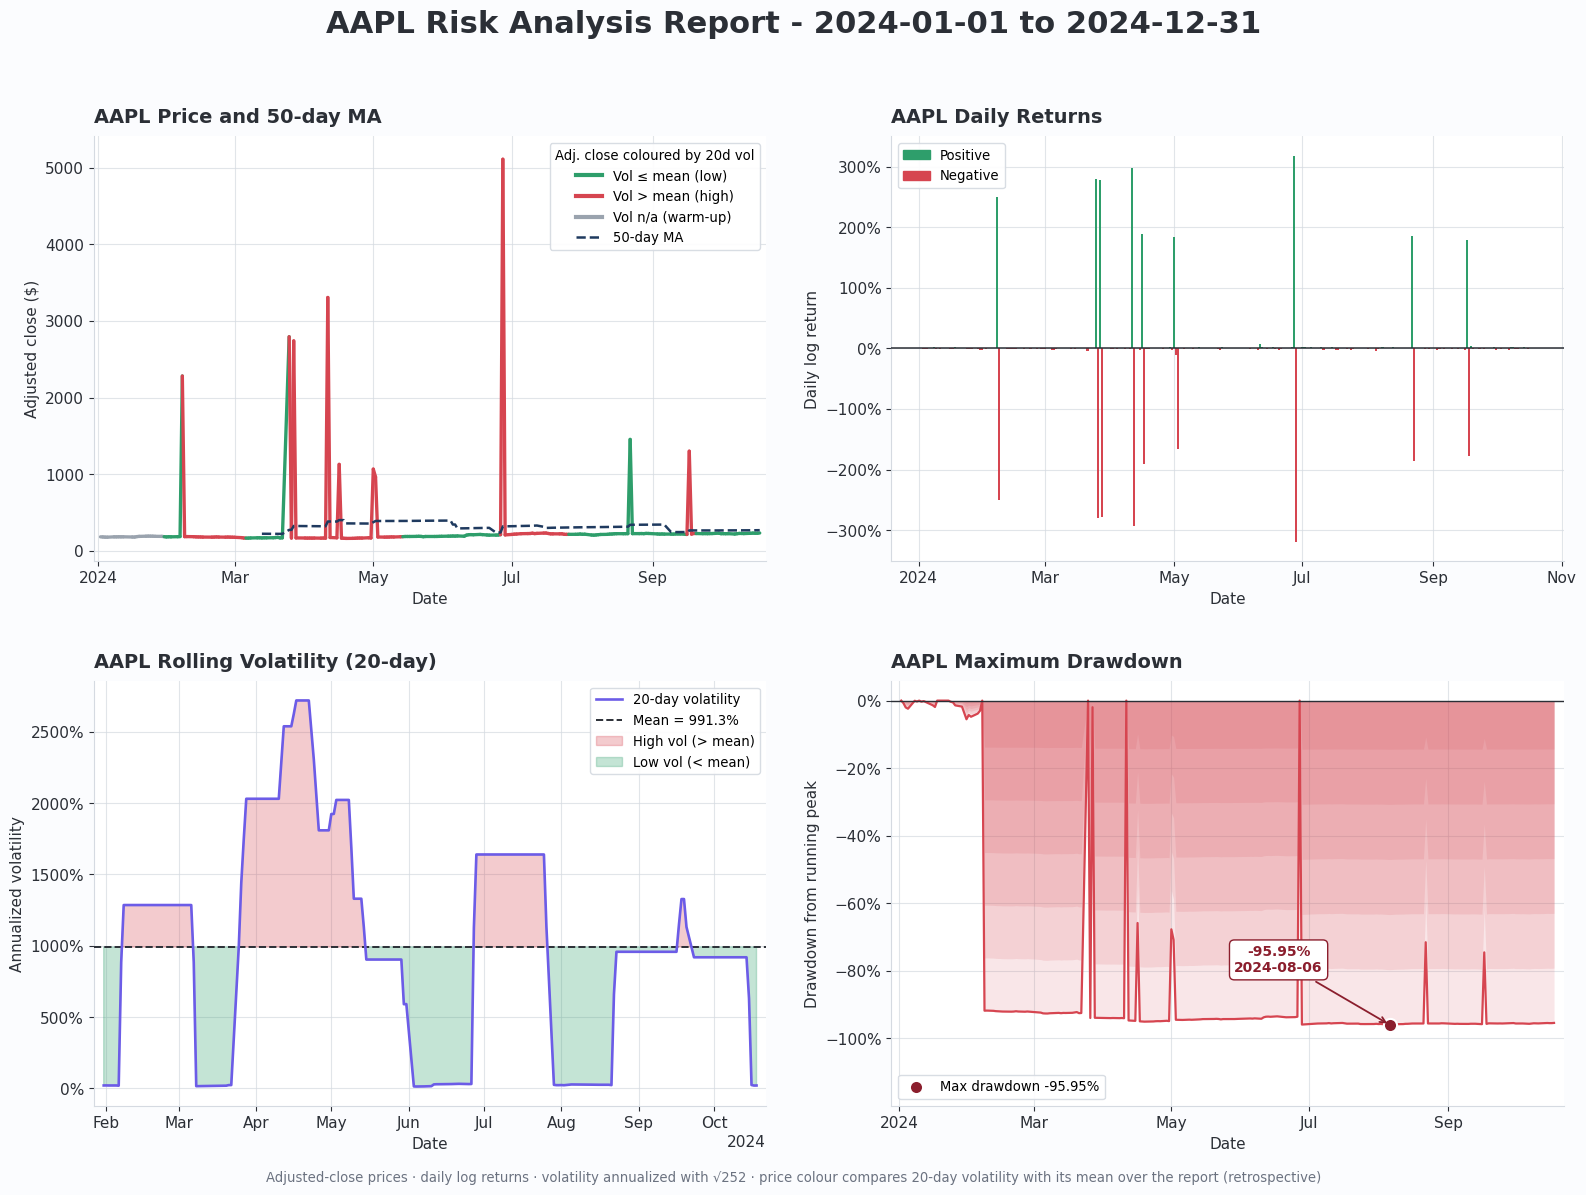

In [11]:
def style_axis(ax, title: str, ylabel: str) -> None:
    """Apply the shared look (title, axis labels, grid, date ticks, spines) to one axis."""
    ax.set_title(title, fontsize=14, color=COLORS["text"], loc="left", pad=10)
    ax.set_xlabel("Date")
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.7)
    ax.set_axisbelow(True)
    locator = mdates.AutoDateLocator(minticks=5, maxticks=9)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)


def plot_risk_dashboard(report: pd.DataFrame, ticker: str, start_date: str, end_date: str):
    """Draw the 2x2 risk dashboard and return the matplotlib Figure.

    Panels: price + 50-day MA coloured by volatility, daily returns, rolling
    volatility with mean line and shaded regimes, and the per-date drawdown with the
    maximum drawdown marked.
    """
    px = report["adj_close"]
    ret = report["log_return"].dropna()
    vol = report[f"vol_{VOL_WINDOW}d"]
    ma = report[f"ma_{MA_WINDOW}d"]
    dd = report["drawdown"]
    mean_vol = vol.mean()

    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    ax_price, ax_ret, ax_vol, ax_dd = axes[0, 0], axes[0, 1], axes[1, 0], axes[1, 1]

    # ---------------- Top left: price + MA, line coloured by volatility -------
    x = mdates.date2num(px.index.values)
    y = px.values.astype(float)
    segments = np.stack([np.column_stack([x[:-1], y[:-1]]), np.column_stack([x[1:], y[1:]])], axis=1)
    seg_vol = vol.values[1:]                      # each segment takes the vol at its end date
    if np.isnan(mean_vol):
        seg_colors = [COLORS["neutral"]] * len(seg_vol)
    else:
        seg_colors = [COLORS["neutral"] if np.isnan(v) else (COLORS["down"] if v > mean_vol else COLORS["up"])
                      for v in seg_vol]
    ax_price.add_collection(LineCollection(segments, colors=seg_colors, linewidths=2.4, capstyle="round", zorder=3))

    has_ma = ma.notna().any()
    if has_ma:
        ax_price.plot(ma.index, ma.values, color=COLORS["ma"], lw=1.8, ls="--", zorder=4)
    else:
        ax_price.text(0.5, 0.06,
                      f"{MA_WINDOW}-day MA unavailable: only {len(px)} prices (needs {MA_WINDOW})",
                      transform=ax_price.transAxes, ha="center", va="bottom", fontsize=10,
                      color=COLORS["ma"], bbox=dict(boxstyle="round,pad=0.4", fc="white", ec=COLORS["grid"]))

    ymin, ymax = np.nanmin(y), np.nanmax(y)
    pad = (ymax - ymin) * 0.06 or max(abs(ymax) * 0.05, 1.0)
    ax_price.set_ylim(ymin - pad, ymax + pad)
    xpad = (x.max() - x.min()) * 0.01 or 1.0
    ax_price.set_xlim(x.min() - xpad, x.max() + xpad)

    handles = [Line2D([0], [0], color=COLORS["up"], lw=3, label="Vol ≤ mean (low)"),
               Line2D([0], [0], color=COLORS["down"], lw=3, label="Vol > mean (high)")]
    if np.isnan(seg_vol).any():
        handles.append(Line2D([0], [0], color=COLORS["neutral"], lw=3, label="Vol n/a (warm-up)"))
    if has_ma:
        handles.append(Line2D([0], [0], color=COLORS["ma"], lw=1.8, ls="--", label=f"{MA_WINDOW}-day MA"))
    ax_price.legend(handles=handles, loc="best", fontsize=9.5, title="Adj. close coloured by 20d vol", title_fontsize=9.5)
    style_axis(ax_price, f"{ticker} Price and 50-day MA", "Adjusted close ($)")

    # ---------------- Top right: daily returns --------------------------------
    bar_colors = np.where(ret.values > 0, COLORS["up"], np.where(ret.values < 0, COLORS["down"], COLORS["neutral"]))
    ax_ret.bar(ret.index, ret.values, width=1.0, color=bar_colors, linewidth=0, zorder=3)
    ax_ret.axhline(0, color=COLORS["text"], lw=1.1, zorder=4)
    ax_ret.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=None))
    ax_ret.legend(handles=[Patch(color=COLORS["up"], label="Positive"), Patch(color=COLORS["down"], label="Negative")],
                  loc="upper left", fontsize=9.5)
    style_axis(ax_ret, f"{ticker} Daily Returns", "Daily log return")

    # ---------------- Bottom left: rolling volatility -------------------------
    ax_vol.plot(vol.index, vol.values, color=COLORS["vol"], lw=1.9, zorder=4, label=f"{VOL_WINDOW}-day volatility")
    if vol.notna().any():
        ax_vol.axhline(mean_vol, color=COLORS["text"], ls="--", lw=1.4, zorder=3, label=f"Mean = {mean_vol:.1%}")
        ax_vol.fill_between(vol.index, vol.values, mean_vol, where=(vol > mean_vol).values, interpolate=True,
                            color=COLORS["down"], alpha=0.28, zorder=2, label="High vol (> mean)")
        ax_vol.fill_between(vol.index, vol.values, mean_vol, where=(vol < mean_vol).values, interpolate=True,
                            color=COLORS["up"], alpha=0.28, zorder=2, label="Low vol (< mean)")
    if vol.notna().any() and (vol.max() - vol.min()) < 1e-9:      # flat volatility: avoid a degenerate axis
        ax_vol.set_ylim(0, max(vol.max() * 2, 0.05))
    ax_vol.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=None))
    ax_vol.legend(loc="best", fontsize=9.5)
    style_axis(ax_vol, f"{ticker} Rolling Volatility (20-day)", "Annualized volatility")
    ax_vol.margins(x=0.015)

    # ---------------- Bottom right: drawdown ----------------------------------
    n_layers = 6        # layered transparent fills → light-to-dark red/pink gradient toward the peak line
    for frac in np.linspace(1.0, 0.15, n_layers):
        ax_dd.fill_between(dd.index, 0, dd.values * frac, color=COLORS["down"], alpha=0.13, linewidth=0, zorder=2)
    ax_dd.plot(dd.index, dd.values, color=COLORS["down"], lw=1.6, zorder=3)
    ax_dd.axhline(0, color=COLORS["text"], lw=1.0, zorder=4)

    max_dd, max_dd_date = dd.min(), dd.idxmin()
    ax_dd.scatter([max_dd_date], [max_dd], s=90, color="#8B1E2D", edgecolor="white", linewidth=1.5, zorder=6,
                  label=f"Max drawdown {max_dd:.2%}")
    in_right_half = (max_dd_date - dd.index[0]) > (dd.index[-1] - dd.index[0]) / 2
    ax_dd.annotate(f"{max_dd:.2%}\n{max_dd_date:%Y-%m-%d}", xy=(max_dd_date, max_dd),
                   xytext=(-80 if in_right_half else 30, 38 if max_dd < 0 else -45), textcoords="offset points", fontsize=10,
                   fontweight="bold", color="#8B1E2D", ha="center",
                   bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="#8B1E2D", lw=1),
                   arrowprops=dict(arrowstyle="->", color="#8B1E2D", lw=1.3), zorder=7)
    span = max(-max_dd, 0.01)
    ax_dd.set_ylim(-span * 1.25, span * 0.06)
    ax_dd.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=None))
    ax_dd.legend(loc="lower left", fontsize=9.5)
    style_axis(ax_dd, f"{ticker} Maximum Drawdown", "Drawdown from running peak")
    ax_dd.margins(x=0.015)

    # ---------------- Figure-level title & footnote ---------------------------
    fig.suptitle(f"{ticker} Risk Analysis Report - {start_date} to {end_date}",
                 fontsize=22, fontweight="bold", color=COLORS["text"], y=0.985)
    fig.text(0.5, 0.008,
             "Adjusted-close prices · daily log returns · volatility annualized with √252 · "
             "price colour compares 20-day volatility with its mean over the report (retrospective)",
             ha="center", fontsize=9.5, color="#6B7280")
    fig.tight_layout(rect=[0, 0.02, 1, 0.955], h_pad=3, w_pad=2.5)
    return fig


fig = plot_risk_dashboard(report, ticker, start_date, end_date)
plt.show()

## 2.5 Summary Statistics Table
- **Total return** = last adj. close ÷ first adj. close − 1.
- **Annualized return** = `exp(sum(log_returns) × 252 / n) − 1`, with `n` non-missing log returns.
- **Annualized volatility** = `std(log_returns) × √252` over the *whole* period (distinct from the mean *rolling* volatility used for colouring above).
- **Best/worst day** and **average up/down day** use log returns. **Positive days** = positive returns ÷ *all* non-missing returns (zero-return days count in the denominator).
- Anything undefined (e.g. zero volatility, empty up/down subset) is shown as `N/A`.

In [12]:
def compute_summary_stats(adj_close: pd.Series, log_returns: pd.Series,
                          risk_free_rate: float = RISK_FREE_RATE) -> dict:
    """Compute the report's summary statistics as raw fractions (not formatted).

    Parameters
    ----------
    adj_close : pd.Series
        Adjusted close prices for the report period.
    log_returns : pd.Series
        Daily log returns of ``adj_close`` (the leading ``NaN`` is ignored).
    risk_free_rate : float
        Annual risk-free rate used by the Sharpe ratio.

    Returns
    -------
    dict
        Keys: total_return, annualized_return, annualized_volatility, sharpe_ratio,
        max_drawdown, best_day, worst_day, positive_days, avg_up_day, avg_down_day.
        Values are floats (fractions; ``NaN`` where undefined).
    """
    r = log_returns.dropna()
    n = len(r)
    up, down = r[r > 0], r[r < 0]
    nan = np.nan

    return {
        "total_return": adj_close.iloc[-1] / adj_close.iloc[0] - 1 if len(adj_close) >= 2 else nan,
        "annualized_return": float(np.exp(r.sum() * TRADING_DAYS / n) - 1) if n > 0 else nan,
        "annualized_volatility": float(r.std() * np.sqrt(TRADING_DAYS)) if n >= 2 else nan,
        "sharpe_ratio": calculate_sharpe_ratio(r, risk_free_rate),
        "max_drawdown": float(calculate_max_drawdown(adj_close).min()),
        "best_day": float(r.max()) if n > 0 else nan,
        "worst_day": float(r.min()) if n > 0 else nan,
        "positive_days": float((r > 0).sum() / n) if n > 0 else nan,
        "avg_up_day": float(up.mean()) if len(up) else nan,
        "avg_down_day": float(down.mean()) if len(down) else nan,
    }


def _fmt(value: float, kind: str) -> str:
    """Format a raw statistic for display ('N/A' for missing/undefined values)."""
    if value is None or not np.isfinite(value):
        return "N/A"
    return {"signed_pct": f"{value:+.2%}", "pct": f"{value:.2%}", "pct1": f"{value:.1%}",
            "ratio": f"{value:.2f}"}[kind]


summary_raw = compute_summary_stats(report["adj_close"], report["log_return"], RISK_FREE_RATE)

rows = [
    ("Total Return",          _fmt(summary_raw["total_return"], "signed_pct")),
    ("Annualized Return",     _fmt(summary_raw["annualized_return"], "signed_pct")),
    ("Annualized Volatility", _fmt(summary_raw["annualized_volatility"], "pct")),
    ("Sharpe Ratio",          _fmt(summary_raw["sharpe_ratio"], "ratio")),
    ("Maximum Drawdown",      _fmt(summary_raw["max_drawdown"], "pct")),
    ("Best Day",              _fmt(summary_raw["best_day"], "signed_pct")),
    ("Worst Day",             _fmt(summary_raw["worst_day"], "signed_pct")),
    ("Positive Days",         _fmt(summary_raw["positive_days"], "pct1")),
    ("Average Up Day",        _fmt(summary_raw["avg_up_day"], "signed_pct")),
    ("Average Down Day",      _fmt(summary_raw["avg_down_day"], "signed_pct")),
]

print(f"{ticker} | {first_obs:%Y-%m-%d} → {last_obs:%Y-%m-%d} | {n_days} trading days\n")
print(f"{'Metric':<24}  {'Value':>8}")
print(f"{'-' * 24}  {'-' * 8}")
for metric, value in rows:
    print(f"{metric:<24}  {value:>8}")

AAPL | 2024-01-02 → 2024-10-18 | 202 trading days

Metric                       Value
------------------------  --------
Total Return               +27.07%
Annualized Return          +35.03%
Annualized Volatility     1166.41%
Sharpe Ratio                  0.02
Maximum Drawdown           -95.95%
Best Day                  +317.75%
Worst Day                 -318.99%
Positive Days                55.2%
Average Up Day             +20.38%
Average Down Day           -24.87%


## Automation hand-off (Part 3)
Records the report's headline numbers as a single named **scrapbook** output, `report_metrics`, so `03_run_all_stocks.py` can read them from *this* executed notebook (rather than scanning files). The cell is skipped harmlessly if `scrapbook` is not installed, so the notebook still runs standalone. Values are raw fractions; undefined values (`NaN`) are stored as `null`.

In [13]:
def _json_safe(value):
    """Convert numpy/pandas scalars to plain Python values; NaN/inf become None (JSON null)."""
    if value is None:
        return None
    if isinstance(value, (float, np.floating)):
        return float(value) if np.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    return value


report_metrics = {k: _json_safe(v) for k, v in {
    # identity + what was actually analysed (used by the runner to detect stale/mismatched reports)
    "ticker": ticker,
    "start_date": start_date,
    "end_date": end_date,
    # actual coverage of this report (may be shorter than the requested window)
    "first_obs": f"{first_obs:%Y-%m-%d}",
    "last_obs": f"{last_obs:%Y-%m-%d}",
    "n_days": n_days,
    "n_returns": int(report["log_return"].notna().sum()),
    # headline statistics (fractions)
    "avg_daily_return": report["log_return"].mean(),      # mean daily log return
    "avg_volatility": mean_vol,                            # mean of the 20-day rolling volatility
    "max_drawdown": summary_raw["max_drawdown"],
    "sharpe_ratio": summary_raw["sharpe_ratio"],
    "total_return": summary_raw["total_return"],
    "annualized_return": summary_raw["annualized_return"],
    "annualized_volatility": summary_raw["annualized_volatility"],
}.items()}

try:
    import scrapbook as sb
    sb.glue("report_metrics", report_metrics)
    print("Recorded 'report_metrics' with scrapbook.")
except ImportError:
    print("scrapbook is not installed - skipping the Part 3 hand-off (the report above is unaffected).")

Recorded 'report_metrics' with scrapbook.
